In [ ]:
import os
import torch
import torchvision
import tarfile
from torchvision.datasets.utils import download_url
from torch.utils.data import random_split

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import kagglehub

# Download latest version
path = kagglehub.dataset_download("akash2sharma/tiny-imagenet")

print("Path to dataset files:", path)

100%|██████████| 474M/474M [00:07<00:00, 68.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1


In [ ]:
datapath = "/root/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1/tiny-imagenet-200"

In [ ]:
os.listdir(datapath)

['words.txt', 'wnids.txt', 'val', 'tiny-imagenet-200', 'train', 'test']

In [ ]:
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor

train_ds = ImageFolder(datapath+'/train', transform=ToTensor())
val_ds = ImageFolder(datapath + '/val', transform=ToTensor())
test = ImageFolder(datapath+'/test', transform= ToTensor())

In [ ]:
train_ds, val_ds, test

(Dataset ImageFolder
     Number of datapoints: 100000
     Root location: /root/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1/tiny-imagenet-200/train
     StandardTransform
 Transform: ToTensor(),
 Dataset ImageFolder
     Number of datapoints: 10000
     Root location: /root/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1/tiny-imagenet-200/val
     StandardTransform
 Transform: ToTensor(),
 Dataset ImageFolder
     Number of datapoints: 10000
     Root location: /root/.cache/kagglehub/datasets/akash2sharma/tiny-imagenet/versions/1/tiny-imagenet-200/test
     StandardTransform
 Transform: ToTensor())

In [ ]:
from torch.utils.data.dataloader import DataLoader

batch_size = 128

train_dl = DataLoader(train_ds, batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size, shuffle=True, num_workers=4, pin_memory=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
class ImageClassification(nn.Module):
  def training_step(self, batch):
    images, labels = batch
    out = self(images)
    loss = F.cross_entropy(out, labels)
    return loss
  def validation_step(self, batch):
    images, labels = batch
    out = self(images)
    loss = F.cross_entropy(out, labels)
    acc = self.accuracy(out, labels)
    return {'val_loss': loss.detach(), 'val_acc': acc}
  def validation_epoch_end(self, outputs):
    batch_losses = [x['val_loss'] for x in outputs]
    epoch_loss = torch.stack(batch_losses).mean()
    batch_accs = [x['val_acc'] for x in outputs]
    epoch_accs = torch.stack(batch_accs).mean()
    return {'val_loss': epoch_loss.item(), 'val_acc':epoch_accs.item()}
  def epoch_end(self, epoch, result):
    print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}, val_acc:{:.4f}".format(
      epoch, result['train_loss'], result['val_loss'], result['val_acc']
    ))
  @torch.no_grad()
  def evaluate(self, val_loader):
    outputs = [self.validation_step(batch) for batch in val_loader]
    return self.validation_epoch_end(outputs)
  def accuracy(self, outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds==labels).item()/ len(preds))

In [ ]:
class imagenet(ImageClassification):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, stride=1 ,padding=1 ),
        nn.ReLU(),
        nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),


        nn.Conv2d(64, 128, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.Conv2d(128, 128, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),

        nn.Conv2d(128, 256, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.Conv2d(256,256, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),

        nn.Conv2d(256, 512, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.Conv2d(512, 512, kernel_size=3, stride=1 ,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),

        nn.Flatten(),
        nn.Linear(512*4*4, 1028),
        nn.ReLU(),
        nn.Linear(1028, 2056),
        nn.ReLU(),
        nn.Linear(2056,200)
    )
  def forward(self, xb):
    return self.network(xb)


In [ ]:
def get_default_device():
    """Pick GPU if available, else CPU"""
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def to_device(data, device):
    """Move tensor(s) to chosen device"""
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    """Wrap a dataloader to move data to a device"""
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        """Yield a batch of data after moving it to device"""
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        """Number of batches"""
        return len(self.dl)

In [ ]:
device = get_default_device()
device

device(type='cuda')

In [ ]:
device = torch.device( 'cuda')

In [ ]:
device

device(type='cuda')

In [ ]:
model = imagenet()

In [ ]:
train_dl = DeviceDataLoader(train_dl, device)
val_dl = DeviceDataLoader(val_dl, device)
to_device(model, device);

In [ ]:
model = to_device(imagenet(), device)

In [ ]:
model.evaluate(val_dl)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


{'val_loss': 5.317443370819092, 'val_acc': 0.0}

In [ ]:
def fit(epochs, lr, model, train_loader, val_loader, opt_func=torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), lr)
    for epoch in range(epochs):
        # Training Phase
        model.train()
        train_losses = []
        for batch in train_loader:
            loss = model.training_step(batch)
            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        # Validation phase
        result = model.evaluate(val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        model.epoch_end(epoch, result)
        history.append(result)
    return history

In [ ]:
num_epochs = 10
opt_func = torch.optim.Adam
lr = 0.001

history = fit(num_epochs, lr, model, train_dl, val_dl, opt_func)

Epoch [0], train_loss: 5.2991, val_loss: 5.2995, val_acc:0.0000
Epoch [1], train_loss: 5.2989, val_loss: 5.3000, val_acc:0.0000
Epoch [2], train_loss: 5.2989, val_loss: 5.3099, val_acc:0.0000
Epoch [3], train_loss: 5.2989, val_loss: 5.2992, val_acc:0.0000
Epoch [4], train_loss: 5.2989, val_loss: 5.2985, val_acc:0.0000
Epoch [5], train_loss: 5.2989, val_loss: 5.2975, val_acc:0.0000
Epoch [6], train_loss: 5.2989, val_loss: 5.2946, val_acc:0.0000
Epoch [7], train_loss: 5.2989, val_loss: 5.2989, val_acc:0.0000
Epoch [8], train_loss: 5.2989, val_loss: 5.3099, val_acc:0.0000
Epoch [9], train_loss: 5.2989, val_loss: 5.3054, val_acc:0.0000


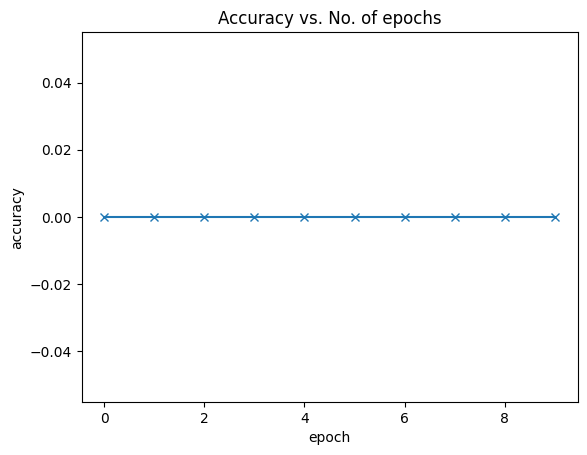

In [ ]:
def plot_accuracies(history):
    accuracies = [x['val_acc'] for x in history]
    plt.plot(accuracies, '-x')
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title('Accuracy vs. No. of epochs');

plot_accuracies(history)

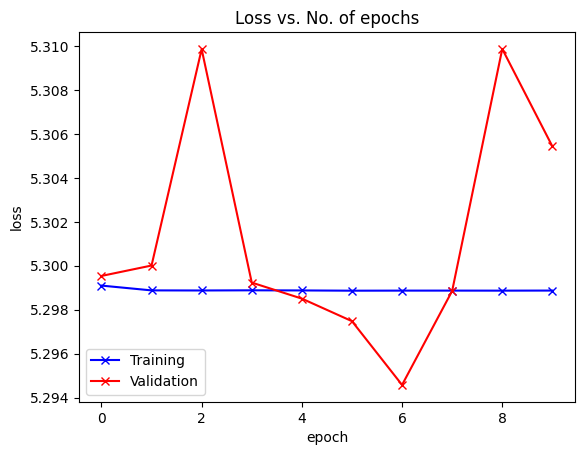

In [ ]:
def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx')
    plt.plot(val_losses, '-rx')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss vs. No. of epochs');

plot_losses(history)

In [ ]:
def predict_image(img, model):
    # Convert to a batch of 1
    xb = to_device(img.unsqueeze(0), device)
    # Get predictions from model
    yb = model(xb)
    # Pick index with highest probability
    _, preds  = torch.max(yb, dim=1)
    # Retrieve the class label
    return dataset.classes[preds[0].item()]

In [ ]:
test_loader = DeviceDataLoader(DataLoader(test, batch_size*2), device)
result = model.evaluate(test_loader)
result

{'val_loss': 5.305430889129639, 'val_acc': 0.0}

In [ ]:
torch.save(model.state_dict(), 'tinyimagenet-cnn.pth')